# 01. Обзор данных

Цель: понять, **какие данные у нас есть и чем они опасны для модели**, до того как строить модели.
Под каждым графиком — вывод в формате «что видим → что значит для модели».

Источники: WDI (готов), AidData GCDF 3.0 и BACI (будут добавлены).

In [2]:
import sys
from pathlib import Path

# Ноутбук лежит в notebooks/, а пакет src — в корне проекта
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.etl.wdi import load_wdi, to_wide

sns.set_theme(style="white", font_scale=0.9)
long = load_wdi()
wide = to_wide(long)
long.shape, wide.shape

((9504, 4), (1188, 10))

## 1. Карта пропусков: страна × год

**Вопрос:** где пропуски — разбросаны случайно или собраны в отдельных странах и годах?

Цвет клетки — сколько из 7 показателей пусто в этой стране в этом году
(население заполнено всегда, поэтому его не считаем). Страны отсортированы по общему числу пропусков:
самые «дырявые» — сверху.

Как читать:
- **горизонтальная тёмная полоса** — страна плохо покрыта весь период;
- **вертикальная полоса** — проблема года (например, последние годы ещё не обновлены);
- **тёмный угол** — у страны нет данных в начале или в конце периода (новая страна, война).

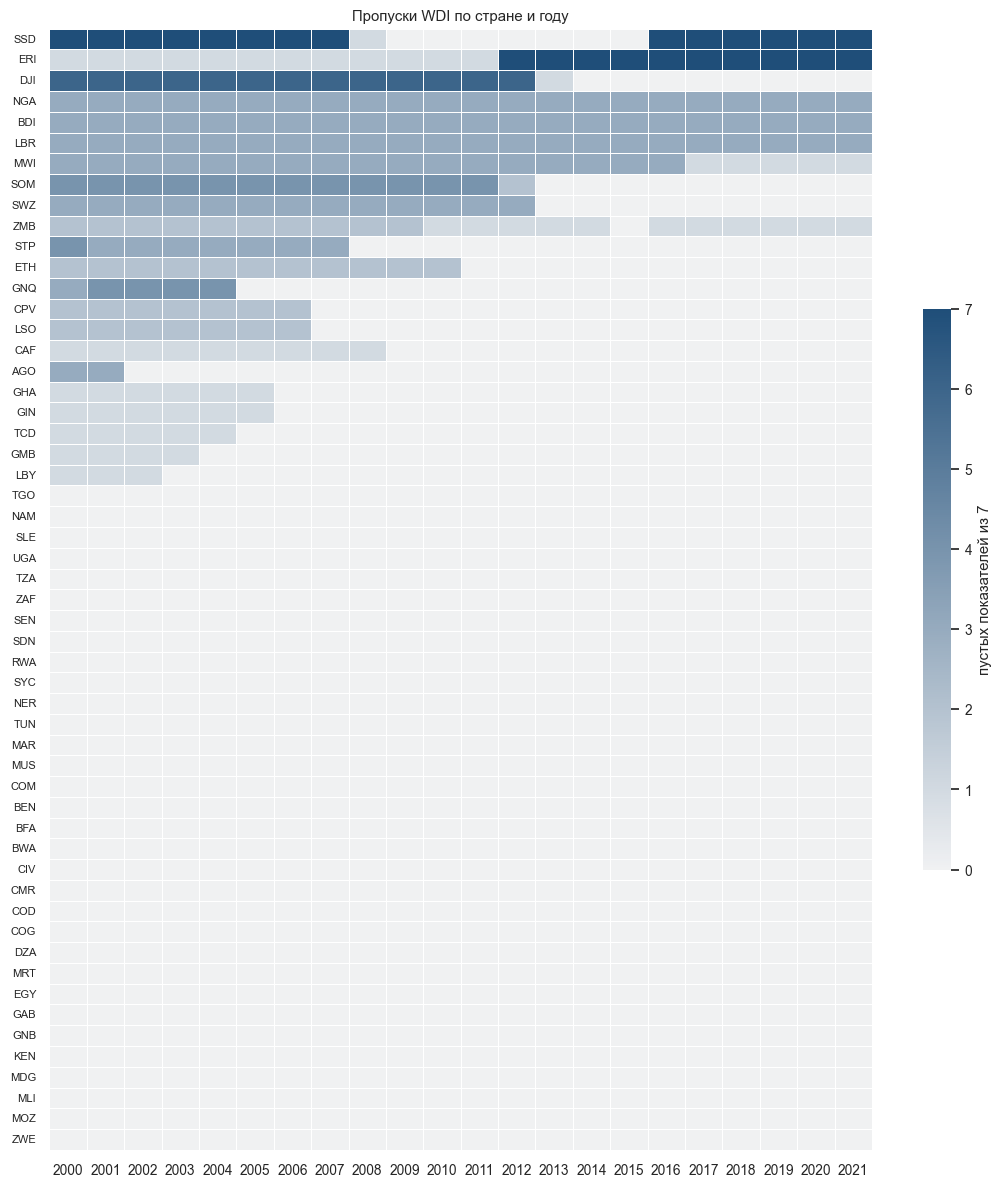

In [3]:
cols = [c for c in wide.columns if c not in ("iso3", "year", "pop")]
n_missing = (
    wide.assign(n_missing=wide[cols].isna().sum(axis=1))
        .pivot(index="iso3", columns="year", values="n_missing")
)
n_missing = n_missing.loc[n_missing.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 12))
sns.heatmap(
    n_missing, ax=ax,
    cmap=sns.light_palette("#1f4e79", as_cmap=True),  # один оттенок: светлый = полно, тёмный = пусто
    vmin=0, vmax=len(cols), linewidths=0.5, linecolor="white",
    cbar_kws={"label": f"пустых показателей из {len(cols)}", "shrink": 0.5},
)
ax.set(title="Пропуски WDI по стране и году", xlabel="", ylabel="")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

Сводка: доля пустых страна-лет по каждому показателю и страны, где показатель пуст весь период.

In [4]:
share = wide[cols].isna().mean().sort_values(ascending=False).rename("доля пропусков")
always_empty = {c: sorted(wide.loc[wide[c].isna()].groupby("iso3").size().loc[lambda s: s == 22].index)
                for c in cols}
pd.DataFrame({"доля пропусков": share.round(3),
              "пусто все 22 года": pd.Series(always_empty)})

,доля пропусков,пусто все 22 года
exports,0.210,"[BDI, ERI, LBR, MWI, NGA]"
exports_pct,0.150,"[BDI, LBR, NGA]"
gdi,0.155,"[BDI, LBR, NGA]"
gdp,0.031,[]
gdp_pc,0.031,[]
growth,0.033,[]
rents,0.035,[]


### Вывод

*Видим что:* У SSD есть большой пропуск до 2008 и после 2016 и у ERI после 2012 отсутсвуют показания. 
NGA / LBR / MWI / BDI  равномерно пропущены значения в большой массе. Мы видим что эти значения дают пустые exports / exports_pct / gdi

У большого количества странно есть пропуски (Темный угол вверху) видим что пропуски систематически на многих страннах, это связано не с ошибкой а с специфика сбора: слабая статистика в нестабильных странах. 

*Что значит для модели:* пропуски MNAR, связаны с нестабильностью, поэтому выбрасывание строк с NaN смещает выборку в сторону стабильных стран. Направление смещения эффекта заранее неизвестно (выпадает и Нигерия — крупный получатель кредитов),проверим после AidData. Каждая переменная в модели меняет выборку, поэтому: основной исход — log(gdp_pc) (покрытие 97%); 
экспорт — из BACI; gdi не берём в контроль (выбрасывает NGA/BDI/LBR и является медиатором). В робастности — сравнить     
результат на сбалансированной подвыборке.


## 2. Рост ВВП по годам: медиана и межквартильный размах

**Вопрос:** есть ли годы, когда рост проседает сразу у всех стран (общие шоки), и как меняется разброс между странами?

- **Линия** — медиана `growth` по ~52 странам за год; **полоса** — от 25-го до 75-го перцентиля (IQR, «средние 50% стран»).
- **Серый пунктир** — среднее. Там, где оно уходит от медианы, год тянут несколько стран-выбросов.

*Мой прогноз до графика:* провалы в 2008–09 (мировой финансовый кризис) и 2020 (COVID), потому что это общие кризисы; в кризис полоса станет уже.

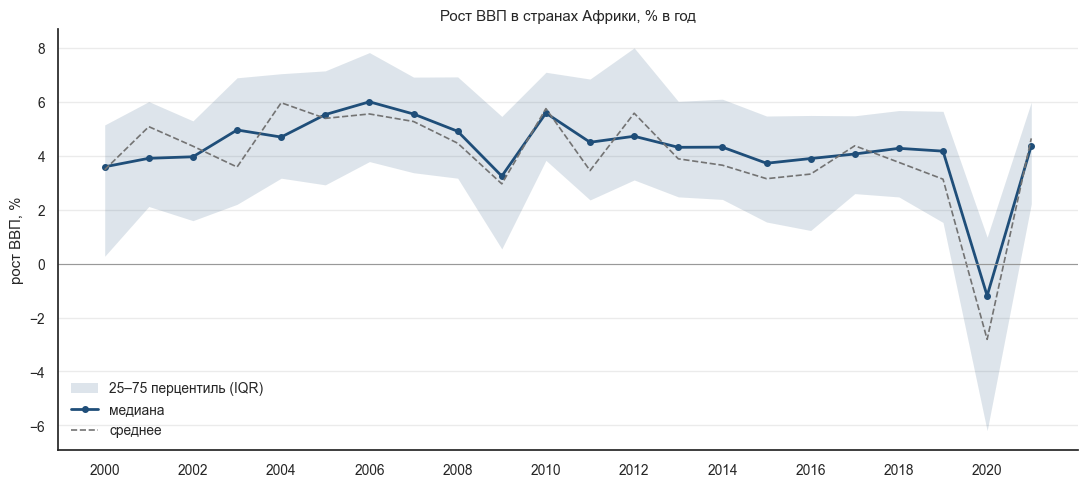

In [3]:
stats = (
    wide.groupby("year")["growth"]
        .agg(median="median", mean="mean",
             q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="count")
)
stats["iqr"] = stats["q75"] - stats["q25"]

BLUE = "#1f4e79"
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(stats.index, stats["q25"], stats["q75"], color=BLUE, alpha=0.15, linewidth=0,
                label="25–75 перцентиль (IQR)")
ax.plot(stats.index, stats["median"], color=BLUE, linewidth=2, marker="o", markersize=4, label="медиана")
ax.plot(stats.index, stats["mean"], color="0.45", linewidth=1.2, linestyle="--", label="среднее")
ax.axhline(0, color="0.6", linewidth=0.8)

ax.set(title="Рост ВВП в странах Африки, % в год", xlabel="", ylabel="рост ВВП, %",
       xticks=stats.index[::2])
ax.grid(axis="y", color="0.92")
sns.despine(ax=ax)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

Таблица к графику: медиана, среднее, IQR и число стран с данными по годам.

In [4]:
stats.round(1)

,median,mean,q25,q75,n,iqr
year,,,,,,
2000,3.6,3.5,0.3,5.1,52,4.9
2001,3.9,5.1,2.1,6.0,52,3.9
2002,4.0,4.4,1.6,5.3,52,3.7
2003,5.0,3.6,2.2,6.9,52,4.7
2004,4.7,6.0,3.2,7.0,52,3.9
2005,5.5,5.4,2.9,7.1,52,4.2
2006,6.0,5.5,3.8,7.8,52,4.0
2007,5.5,5.3,3.4,6.9,52,3.5
2008,4.9,4.5,3.2,6.9,52,3.8


### Вывод 2

*Видим что:* Видим что на всех повлиял кризис связанный с COVID в 2020 году и в 2009 до Африки дошёл кризис 2008 года. Напрямую Африка с Америкой не связана: мы увидели эффект кризиса который начался в 2008 году в американских банках уже в 2009 году в Африке.

Прогноз не подтвердился, потому что полоса стала шире, разное влияние на страны с разной структурой ВВП, и кризис который мы привыкли видеть в 2008 году на Африке отразился только в 2009, через падение цен на сырьё и спроса на экспорт, а ещё через сокращение денежных переводов от мигрантов.
Важно, в 2014–2017 среднее и медиана почти не изменилась, а вот ширина канала изменилась: её нижняя граница заметно просела, это связано с ценами на нефть и полезные ископаемые которые отразились на отдельных странах, но не на всей Африке.

Сила кризиса - в 2009 году кризис отразился только косвенно, а вот в 2020 году затронул уже сильнее (единственный год с отрицательной медианой).

*Что значит для модели:*
Мы строили этот график чтобы проследить наличие единого драйвера или якоря для всех экономик разом, видим что общие шоки — 2009 и 2020 стали испытанием для всего континента, но с разной силой.
Важно учесть это как фиксированный эффект года (FE) то есть как провал в 2020 году это кризис а не отсутствие кредитов от Китая.
Шок 2015–16 ударил только по сырьевым экспортёрам, и FE года его не уберёт → в модель добавляем ресурсную ренту (значение до treatment), в робастности — оценка без сырьевых экспортёров
